In [14]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from nilearn import plotting
from nilearn.image import resample_to_img
from nilearn.maskers import NiftiMasker
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr

if not hasattr(np, "row_stack"):  # brainsmash 0.11usa un alias que NumPy 2.5 ya quito
    np.row_stack = np.vstack

from brainsmash.mapgen.base import Base

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import estilo as E

E.aplicar_estilo()

pd.set_option("display.width", 140)

GENES = {
    "CNR1": ("CB1", "receptor"),
    "CNR2": ("CB2", "receptor"),
    "DAGLA": ("DAGLα", "fabrica 2-AG"),
    "DAGLB": ("DAGLβ", "fabrica 2-AG"),
    "MGLL": ("MAGL", "degrada 2-AG"),
    "ABHD6": ("ABHD6", "degrada 2-AG"),
    "ABHD12": ("ABHD12", "degrada 2-AG"),
    "NAPEPLD": ("NAPE-PLD", "fabrica anandamida"),
    "FAAH": ("FAAH", "degrada anandamida"),
}





In [15]:
# Celda 2 Las regiones del atlas y su centro en milimetros
atlas = nib.load(RAW / "atlas-desikankilliany.nii.gz")
regiones = pd.read_csv(RAW / "atlas-desikankilliany.csv").set_index("id")

SUB = { # nombre en el atlas: (nombre en ENIGMA, nombre en español)
    "thalamusproper": ("thal", "talamo"),
    "caudate": ("caud" "caudado"),
    "putamen": ("put", "putamen"),
    "pallidum": ("pal", "palido"),
    "accumbensarea": ("accumb", "accubens"),
    "hippocampus": ("hippo", "hipocampo"),
    "amygdala": ("amyg", "amigdala")
}

def nombres(r):
    if r.structure == "cortex":
        return f"{r.hemisphere}_{r.label}", r.label
    if r.label in SUB:
        return f"{r.hemisphere}{SUB[r.label][0]}", SUB[r.label][1]
    return None, r.label

regiones[["enigma", "nombre"]] = regiones.apply(nombres, axis=1, result_type="expand")
regiones["tejido"] = np.where(regiones.structure == "cortex", "corteza", "subcortical")

voxeles = np.asarray(atlas.dataobj)

centros = { i: nib.affines.apply_affine(atlas.affine, np.argwhere(voxeles == i).mean(axis=0))
    for i in regiones.index}
regiones[["x", "y", "z"]] = pd.DataFrame(centros, index=["x", "y", "z"]).T
print(regiones.groupby(["hemisphere", "tejido"]).size())

hemisphere  tejido     
B           subcortical     1
L           corteza        34
            subcortical     7
R           corteza        34
            subcortical     7
dtype: int64


In [16]:
# Celda 3 Promedio de cada mapa PET dentro de cada region

from nilearn.maskers import NiftiLabelsMasker

def parcelar(archivo):
    pet = resample_to_img(RAW / archivo, atlas, interpolation="continuous", force_resample=True, copy_header=True)
    masker = NiftiLabelsMasker(labels_img=atlas, strategy="mean", standardize=None)
    valores = masker.fit_transform(pet).ravel()
    ids = [int(v) for k, v in masker.region_ids_.items() if k != "background"]
    return pd.Series(valores, index=ids)

regiones["CB1_omar"] = parcelar("CB1_omar_hc77_normandin.nii.gz")
regiones["CB1_fmpep"] = parcelar("CB1_FMPEPd2_hc22_laurikainen.nii")
regiones[["CB1_omar", "CB1_fmpep"]].describe().round(2)

,CB1_omar,CB1_fmpep
count,83.00,83.00
mean,1.30,8.28
std,0.12,1.50
min,0.91,3.26
25%,1.25,7.57
50%,1.32,8.63
75%,1.38,9.44
max,1.63,10.87


In [17]:
# Celda 4 La expresion de los 9 genes; nos quedamos con el hemisferio izquierdo
ahba = pd.read_csv(RAW / "allgenes_stable_r-1.csv", usecols=["label", *GENES]).set_index("label")
tabla = regiones.join(ahba, on="enigma")
izq = tabla[tabla.hemisphere == "L"].copy()
ctx = izq[izq.tejido == "corteza"]
print(izq.shape[0], "regiones:", (izq.tejido == "corteza").sum(), "de corteza y", (izq.tejido == "subcortical").sum(), "subcorticales")
print("Valores faltantes:", int(izq[list(GENES)].isna().sum().sum()))

41 regiones: 34 de corteza y 7 subcorticales
Valores faltantes: 9


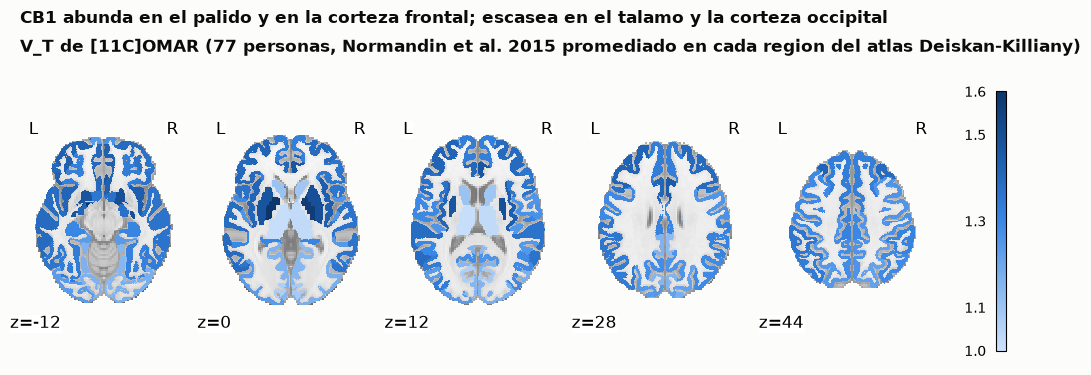

In [19]:
# Celda 5 Figura 1: El mapa de CB1 por region (los dos hemisferios)

mapa = np.zeros(voxeles.shape, dtype="float32")
for i, v in regiones.CB1_omar.items():
    mapa[voxeles == i] = v
img = nib.Nifti1Image(mapa, atlas.affine)

fig = plt.figure(figsize=(10, 3.6))
plotting.plot_stat_map(
    img, display_mode="z", cut_coords=[-12, 0, 12, 28, 44], cmap=E.SECUENCIAL, vmin=1.0, vmax=1.6, symmetric_cbar=False, threshold=0.01, black_bg=False, draw_cross=False, annotate=True, colorbar=True, cbar_tick_format="%.1f", figure=fig, axes=(0, 0, 1, 0.8),
)
fig.text(0.01, 0.95, "CB1 abunda en el palido y en la corteza frontal; escasea en el talamo y la corteza occipital", fontsize=12, fontweight="bold", color=E.TINTA)
fig.text(0.01, 0.87, "V_T de [11C]OMAR (77 personas, Normandin et al. 2015 promediado en cada region del atlas Deiskan-Killiany)", fontsize=12, fontweight="bold", color=E.TINTA)
fig.savefig(FIG / "fig1_mapa_cb1.png")
plt.show()

In [20]:
# Celda 6 Los dos trazadores cuentan la misma historia?
for nombre, df in [("41 regiones", izq), ("corteza(34)", ctx)]:
    r, p = spearmanr(df.CB1_omar, df.CB1_fmpep)
    print(f"OMAR vs FMPEP-d2, {nombre}: rho = {r:.2f}, p{p:.3g}")

OMAR vs FMPEP-d2, 41 regiones: rho = 0.49, p0.00112
OMAR vs FMPEP-d2, corteza(34): rho = 0.46, p0.00589


In [ ]:
# Celda 7 p-valor contra mapas nulos que conversala autocorrelacion espacial
def p_espacial(x, y, coords, n=1000, semilla=42):
    """Spearman entre x e y, y su p de dos colas contra n mapas nulos hechos a partir de x."""
    D= squareform(pdist(coords))
    nulos = Base(x=np.asarray(x), D=D, seed=semilla)(n=n)
    r = spearmanr(x, y).statistic
    r_nulos = np.array([spearmanr(s, y).statistic for s in nulos])
    return r, (1 + np.sum(np.abs(r_nulos) >= abs(r))) / (1 + n)

resultados = []
for trazador in ["CB1_omar", "CB1_fmpep"]:
    for nombre, df in [("corteza", ctx), ("41 regiones", izq)]:
        r, p = p_espacial(df[trazador], df.CNR1, df[["x", "y", "z"]].values)
        resultados.append({"PET": trazador, "regiones": nombre, "rho": round(r, 2), "p_espacial": round(p, 3)})
pd.DataFrame(resultados)

AttributeError: 'int' object has no attribute 'sum'